In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import jv
from matplotlib import colors
#from numpy.ufunc import outer

(-2.0, 2.0)

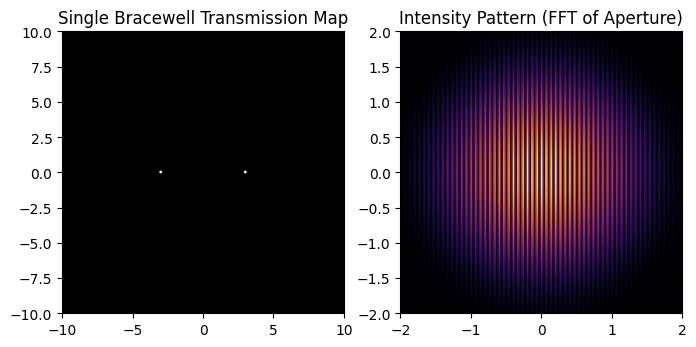

In [2]:
# Single Bracewell Transmission Map
x = np.linspace(-10, 10, 1000)
y = np.linspace(-10, 10, 1000)
X, Y = np.meshgrid(x, y)
Aperture = np.zeros_like(X)
Aperture[np.sqrt((X-3)**2 + Y**2) < 0.1] = 1
Aperture[np.sqrt((X+3)**2 + Y**2) < 0.1] = 1

Aperture_FFT = np.fft.fftshift(np.fft.fft2(Aperture))
Intensity = np.abs(Aperture_FFT)**2

fig, ax = plt.subplots(1, 2, figsize=(8, 12))
ax[0].imshow(Aperture, cmap='gray', extent=[-10, 10, -10, 10])
ax[0].set_title('Single Bracewell Transmission Map')
ax[1].imshow(Intensity, cmap='inferno', extent=[-10, 10, -10, 10])
ax[1].set_title('Intensity Pattern (FFT of Aperture)')
ax[1].set_xlim([-2, 2])
ax[1].set_ylim([-2, 2])

Text(0.5, 1.0, 'Intensity Pattern (FFT of Aperture)')

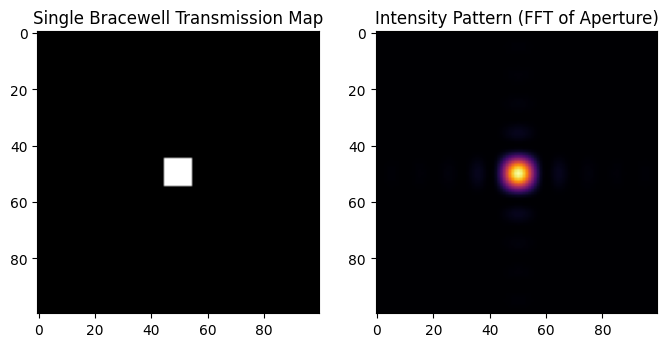

In [3]:
# Single Bracewell Transmission Map

Aperture = np.zeros((100, 100))
Aperture[45:55, 45:55] = 1
Aperture_FFT = np.fft.fftshift(np.fft.fft2(Aperture))
Intensity = np.abs(Aperture_FFT)**2


fig, ax = plt.subplots(1, 2, figsize=(8, 12))
ax[0].imshow(Aperture, cmap='gray')
ax[0].set_title('Single Bracewell Transmission Map')
#ax[0].colorbar()
ax[1].imshow(Intensity, cmap='inferno')
ax[1].set_title('Intensity Pattern (FFT of Aperture)')
#ax[1].colorbar()



In [4]:
# Vk is the complex field amplitude for a telescope sitting at the position pos, in the focal plane of 
# the interferometer. The focal plane is perpendicular to the distance vector of the telescope to the source.
def Vk(pos = (0, 0), lambda_ref = 10e-6, alpha = np.linspace(-0.1, 0.1, 1000), beta = np.linspace(-0.1, 0.1, 1000)):
    xk, yk = pos
    ALPHA, BETA = np.meshgrid(alpha * (np.pi/180) / 3600, beta * (np.pi/180) / 3600, indexing='ij')
    fringe_pattern = np.exp(2*np.pi*1j*(xk*ALPHA + yk*BETA)/lambda_ref)
    return fringe_pattern 

# Transmission map of the single bracewell interferometer
def SBW(baseline, rot_angle, lambda_ref = 10e-6, alpha = np.linspace(-0.1, 0.1, 1000), beta = np.linspace(-0.1, 0.1, 1000)):
    '''
    baseline: distance between the two telescopes
    rot_angle: rotation angle of the interferometer in radians
    lambda_ref: reference wavelength in meters
    alpha: array of alpha angles in degrees
    beta: array of beta angles in degrees
    
    Returns the transmission map of the single bracewell interferometer
    '''
    xk = baseline/2 * np.cos(rot_angle) 
    yk = baseline/2 * np.sin(rot_angle) 
    V1 = Vk(pos=(xk, yk), lambda_ref=lambda_ref, alpha=alpha, beta=beta)
    V2 = Vk(pos=(-xk, -yk), lambda_ref=lambda_ref, alpha=alpha, beta=beta)
    D1 = 1/2*(V1 + np.exp(1j*np.pi)*V2)

    TSBW = np.abs(D1)**2
    return TSBW




def DBW(baseline, rot_angle, q = 6, lambda_ref = 10e-6, alpha = np.linspace(-0.1, 0.1, 1000), beta = np.linspace(-0.1, 0.1, 1000)):
    '''
    baseline: distance between the two telescopes
    rot_angle: rotation angle of the interferometer in radians
    q: ratio of the imaging baseline to the nulling baseline
    lambda_ref: reference wavelength in meters
    alpha: array of alpha angles in degrees
    beta: array of beta angles in degrees

    Returns the transmission map of the double bracewell interferometer
    '''
    xk = baseline/2
    yk = q*baseline/2
    V1 = Vk(pos=(xk*np.cos(rot_angle) - yk*np.sin(rot_angle), yk*np.cos(rot_angle) + xk*np.sin(rot_angle)), lambda_ref=lambda_ref, alpha=alpha, beta=beta)
    V2 = Vk(pos=(-xk*np.cos(rot_angle) - yk*np.sin(rot_angle), yk*np.cos(rot_angle) - xk*np.sin(rot_angle)), lambda_ref=lambda_ref, alpha=alpha, beta=beta)
    V3 = Vk(pos=(xk*np.cos(rot_angle) + yk*np.sin(rot_angle), -yk*np.cos(rot_angle) + xk*np.sin(rot_angle)), lambda_ref=lambda_ref, alpha=alpha, beta=beta)
    V4 = Vk(pos=(-xk*np.cos(rot_angle) + yk*np.sin(rot_angle), -yk*np.cos(rot_angle) - xk*np.sin(rot_angle)), lambda_ref=lambda_ref, alpha=alpha, beta=beta)


    D1 = 1/np.sqrt(4)*(V1 + np.exp(1j*np.pi)*V2)
    D2 = 1/np.sqrt(4)*(V3 + np.exp(1j*np.pi)*V4)

    O1 = 1/np.sqrt(4)*(D1 + np.exp(1j*np.pi/2)*D2)  
    O2 = 1/np.sqrt(4)*(D1 - np.exp(1j*np.pi/2)*D2)

    TDBW = np.abs(O1)**2 - np.abs(O2)**2
    return TDBW






In [5]:

max_fov_angle = 0.2 # in arcseconds
max_fov_angle_rad = max_fov_angle * (np.pi / 180) / 3600 # convert to radians

res = 1000

alpha = np.linspace(-max_fov_angle_rad, max_fov_angle_rad, res)
beta = np.linspace(-max_fov_angle_rad, max_fov_angle_rad, res)



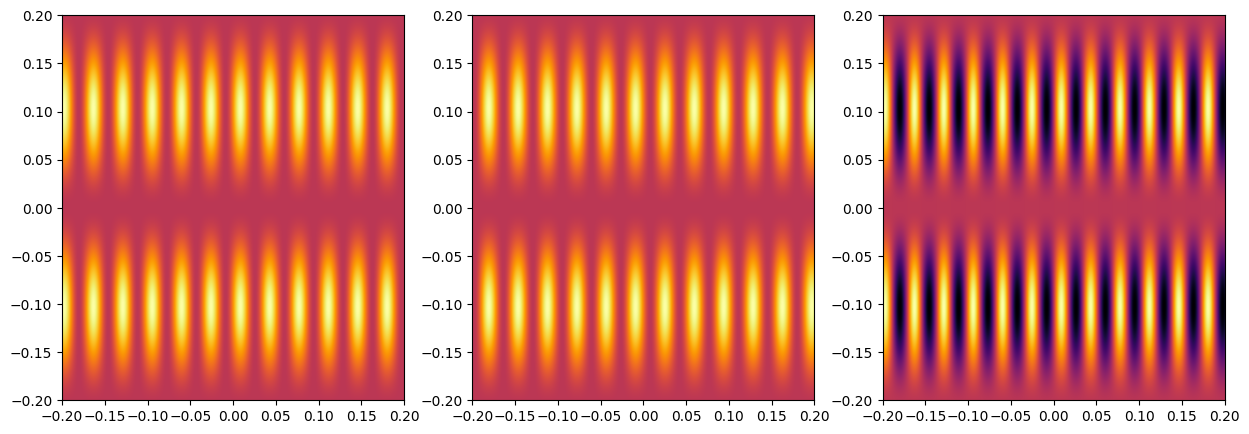

In [6]:
xk = 10
yk = 60
lambda_ref = 10e-6 # 10 microns

# Double Bracewell Transmission Map - Manual Calculation
V1 = Vk(pos=(xk, yk), lambda_ref=lambda_ref)
V2 = Vk(pos=(-xk, yk), lambda_ref=lambda_ref)
V3 = Vk(pos=(xk, -yk), lambda_ref=lambda_ref)
V4 = Vk(pos=(-xk, -yk), lambda_ref=lambda_ref)

D1 = 1/np.sqrt(4)*(V1 + np.exp(1j*np.pi)*V2)
D2 = 1/np.sqrt(4)*(V3 + np.exp(1j*np.pi)*V4)

O1 = 1/np.sqrt(4)*(D1 + np.exp(1j*np.pi/2)*D2)  
O2 = 1/np.sqrt(4)*(D1 - np.exp(1j*np.pi/2)*D2)

TDBW = np.abs(O1)**2 - np.abs(O2)**2


# Single Bracewell Transmission Map
V1 = Vk(pos=(xk, 0), lambda_ref=10e-6) 
V2 = Vk(pos=(-xk, 0), lambda_ref=10e-6)

D1 = 1/2*(V1 + np.exp(1j*np.pi)*V2)
D2 = 1/2*(V1 - np.exp(1j*np.pi)*V2)



vmin = np.min(np.abs(O1)**2 - np.abs(O2)**2)
vmax = np.max(np.abs(O1)**2 - np.abs(O2)**2)
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(np.abs(O1)**2, vmin = vmin, vmax = vmax, aspect='auto', extent=(-max_fov_angle, max_fov_angle, -max_fov_angle, max_fov_angle), cmap='inferno')
plt.subplot(1, 3, 2)
plt.imshow(np.abs(O2)**2, vmin = vmin, vmax = vmax, aspect='auto', extent=(-max_fov_angle, max_fov_angle, -max_fov_angle, max_fov_angle), cmap='inferno')
plt.subplot(1, 3, 3)
plt.imshow(np.abs(O1)**2 - np.abs(O2)**2, vmin = vmin, vmax = vmax, aspect='auto', extent=(-max_fov_angle, max_fov_angle, -max_fov_angle, max_fov_angle), cmap='inferno')
#plt.colorbar()


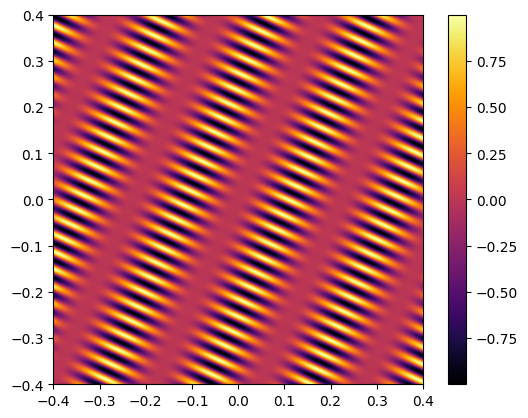

In [7]:
max_fov_angle = 0.4
res = 1000
baseline = 10 # [m]
rot_angle = 20 # [deg]
q = 6 # ratio of the imaging baseline to the nulling baseline
lambda_ref = 10e-6 # reference wavelength in meters


alpha = np.linspace(-max_fov_angle, max_fov_angle, res)
beta = np.linspace(-max_fov_angle, max_fov_angle, res)

TSBW = DBW(baseline = baseline, rot_angle=rot_angle, q = q, lambda_ref=lambda_ref, alpha=alpha, beta=beta) #np.abs(D1)**2
plt.figure()
plt.imshow(TSBW, extent=(min(beta), max(beta), min(alpha), max(alpha)), cmap='inferno')
plt.colorbar()

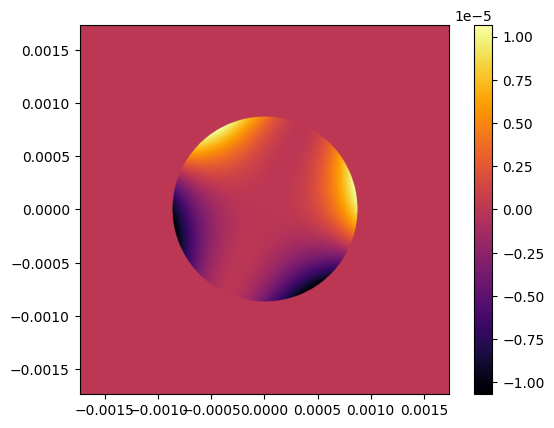

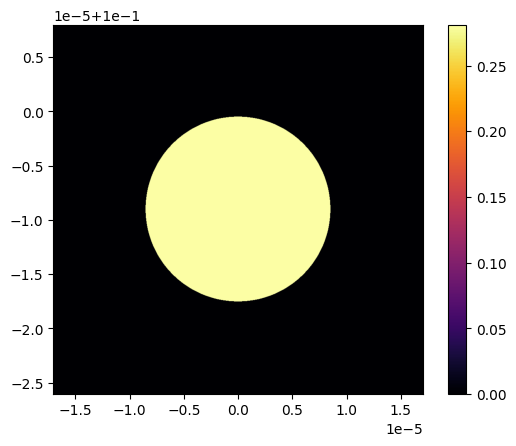

In [8]:

# Planetary System settings
distance_km = 10 * 3.086e13 # 10 parsecs in km

diameter_star_km = 1.3e6
diameter_star_rad = diameter_star_km / distance_km # in radians
diameter_star_arcsec = diameter_star_rad * (180/np.pi) * 3600

planet_star_distance_km = 1.496e8
ang_sep_rad = planet_star_distance_km / distance_km
ang_sep_arcsec = ang_sep_rad * (180/np.pi) * 3600

planet_diameter_km = 12742
planet_diameter_rad = planet_diameter_km / distance_km # in radians
planet_diameter_arcsec = planet_diameter_rad * (180/np.pi) * 3600


planet_pos_rad = np.array([ang_sep_rad, 0]) # in radians
planet_pos_arcsec = np.array([ang_sep_arcsec, 0]) # in arcseconds

# Star on sky
alpha = np.linspace(-diameter_star_arcsec*2, diameter_star_arcsec*2, res)
beta = np.linspace(-diameter_star_arcsec*2, diameter_star_arcsec*2, res)
T_star = DBW(baseline = 10, q=6, rot_angle=20, lambda_ref=10e-6, alpha=alpha, beta=beta) #np.abs(D1)**2

THETA = np.sqrt(alpha[:, None]**2 + beta[None,:]**2)
Im_Star = np.zeros_like(THETA)
Im_Star[THETA < diameter_star_arcsec*1] = 1

plt.figure()
plt.imshow(Im_Star * T_star,cmap='inferno', extent=(min(beta), max(beta), min(alpha), max(alpha)))
plt.colorbar()


# Planet on sky
alpha = np.linspace(-planet_diameter_arcsec*2 + planet_pos_arcsec[0], planet_diameter_arcsec*2 + planet_pos_arcsec[0], res)
beta = np.linspace(-planet_diameter_arcsec*2 + planet_pos_arcsec[1], planet_diameter_arcsec*2 + planet_pos_arcsec[1], res)
T_planet = DBW(baseline = 10, q = 6, rot_angle=20, lambda_ref=10e-6, alpha=alpha, beta=beta) #np.abs(D1)**2

THETA = np.sqrt(alpha[:, None]**2 + beta[None,:]**2)
Im_Planet = np.zeros_like(THETA)
Im_Planet[(alpha[:, None] - planet_pos_arcsec[0])**2 + (beta[None,:] - planet_pos_arcsec[1])**2 < planet_diameter_arcsec**2] = 1


plt.figure()
plt.imshow(Im_Planet * T_planet,cmap='inferno', extent=(min(beta), max(beta), min(alpha), max(alpha)))
plt.colorbar()


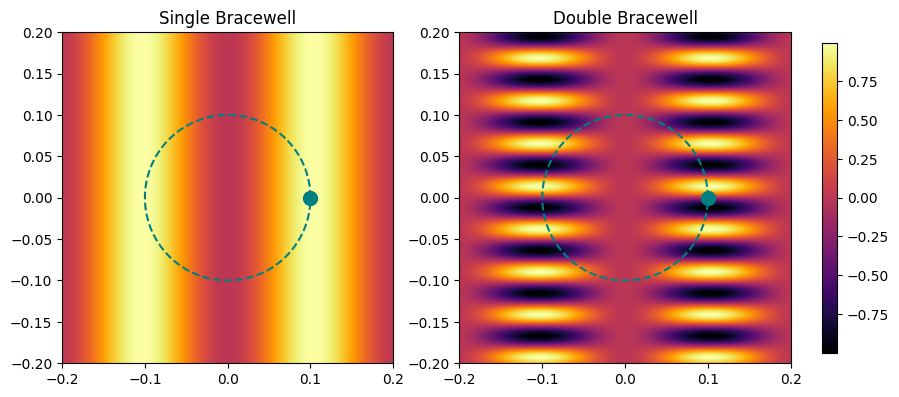

In [9]:
# Star on sky
alpha = np.linspace(-0.2, 0.2, res)
beta = np.linspace(-0.2, 0.2, res)
lambda_ref = 10e-6
T_SBW = SBW(baseline = 10, rot_angle=np.pi/2, lambda_ref=lambda_ref, alpha=alpha, beta=beta) #np.abs(D1)**2
T_DBW = DBW(baseline = 10, q = 4, rot_angle=np.pi/2, lambda_ref=lambda_ref, alpha=alpha, beta=beta) #np.abs(D1)**2
vmin = min(np.min(T_SBW), np.min(T_DBW))
vmax = max(np.max(T_SBW), np.max(T_DBW))
norm = colors.Normalize(vmin=vmin, vmax=vmax)

phi = np.linspace(0, 2*np.pi, res)
x, y = ang_sep_arcsec * np.cos(phi), ang_sep_arcsec * np.sin(phi)

fig, ax = plt.subplots(1,2, figsize=(10,5))
images = []
images.append(ax[0].imshow(T_SBW,cmap='inferno', extent=(min(beta), max(beta), min(alpha), max(alpha)), norm=norm))
ax[0].plot(x, y, color='teal', label='Planet Orbit', linestyle='--')
ax[0].scatter(planet_pos_arcsec[0], planet_pos_arcsec[1], color='teal', label='Planet', s=100)
ax[0].set_title('Single Bracewell')

images.append(ax[1].imshow(T_DBW,cmap='inferno', extent=(min(beta), max(beta), min(alpha), max(alpha)), norm=norm))
ax[1].plot(x, y, color='teal', label='Planet Orbit', linestyle='--')
ax[1].scatter(planet_pos_arcsec[0], planet_pos_arcsec[1], color='teal', label='Planet', s=100)
ax[1].set_title('Double Bracewell')



fig.colorbar(images[0], ax=ax, orientation='vertical', fraction=0.02, pad=0.04)


In [10]:
def SBW_s(t, alpha, beta, baseline, lamda_ref = 10e-6, Omega = 1e-4):
    '''
    t: time in seconds
    alpha: array of alpha angles in degrees
    beta: array of beta angles in degrees
    baseline: distance between the two telescopes
    lamda_ref: reference wavelength in meters
    
    Returns the time signal of a point source at (alpha, beta) as a function of time for a single bracewell
    '''
    alpha_t = np.multiply.outer(np.cos(Omega * t), alpha) - np.multiply.outer(np.sin(Omega * t), beta)
    return np.sin(np.pi * baseline * np.multiply.outer(1/lamda_ref, alpha_t)) ** 2


def DBW_s(t, alpha, beta, baseline, lamda_ref = 10e-6, Omega = 1e-4, q = 6):
    '''
    t: time in seconds
    alpha: array of alpha angles in degrees
    beta: array of beta angles in degrees
    baseline: distance between the two telescopes
    lamda_ref: reference wavelength in meters
    q: ratio of the imaging baseline to the nulling baseline
    
    Returns the time signal of a point source at (alpha, beta) as a function of time for a double bracewell
    '''
    alpha_t = np.multiply.outer(np.cos(Omega * t), alpha) - np.multiply.outer(np.sin(Omega * t), beta)
    beta_t = np.multiply.outer(np.sin(Omega * t), alpha) + np.multiply.outer(np.cos(Omega * t), beta)
    return np.sin(np.pi * baseline * np.multiply.outer(1/lamda_ref, alpha_t))**2 * np.sin(2 * np.pi * q * baseline * np.multiply.outer(1/lamda_ref, beta_t))


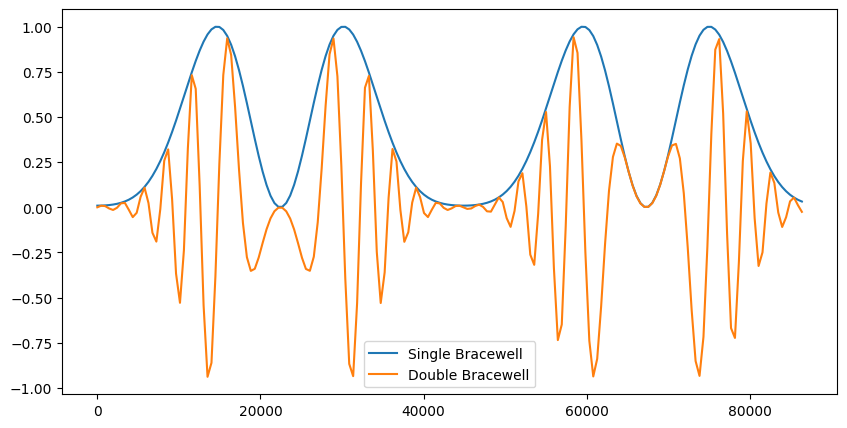

In [124]:
t = np.linspace(0, 1 * 24 * 3600, 180)

alpha = ang_sep_rad
beta = 0
baseline = 20
q = 6

s_SBW = SBW_s(t, alpha, beta, baseline, Omega = 7e-5)
s_DBW = DBW_s(t, alpha, beta, baseline, q=q, Omega = 7e-5)

plt.figure(figsize=(10, 5))
plt.plot(t, s_SBW, label='Single Bracewell')
plt.plot(t, s_DBW, label='Double Bracewell')
plt.legend()

In [125]:
lambdas = np.linspace(5e-6, 20e-6, 50)
s_SBW_lambda = SBW_s(t, alpha, beta, baseline, lamda_ref=lambdas, Omega = 7e-5)
s_DBW_lambda = DBW_s(t, alpha, beta, baseline, lamda_ref=lambdas, q=q, Omega = 7e-5)

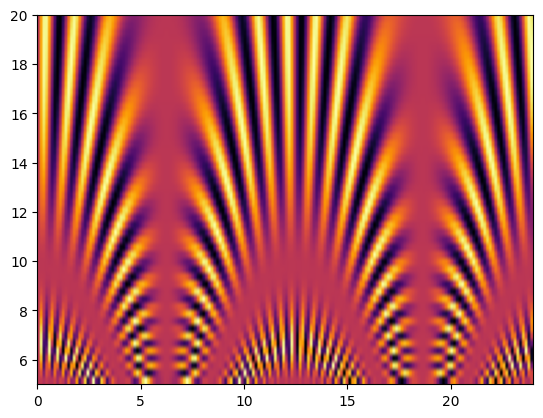

In [126]:
plt.imshow(s_DBW_lambda, extent=(t[0]/3600, t[-1]/3600, lambdas[0]*1e6, lambdas[-1]*1e6), aspect='auto', cmap='inferno', origin = 'lower')

In [127]:
# Transmission map
fov_as = 0.2 # arcsecons
fov_rad = fov_as * (np.pi / 180) / 3600 # convert to radians
res = 200
alpha = np.linspace(-fov_rad, fov_rad, res)
beta = np.linspace(-fov_rad, fov_rad, res)
ALPHA, BETA = np.meshgrid(alpha, beta)

s_SBW_lambda_scenery = SBW_s(t, ALPHA, BETA, baseline, lamda_ref=lambdas, Omega = 7e-5)



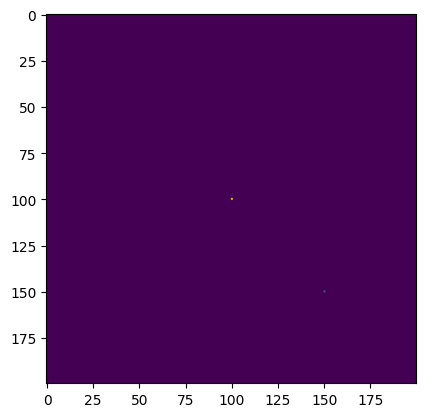

In [128]:
# Create scenery
IM = np.zeros_like(ALPHA)
IM[int(1/2*res), int(1/2*res)] += 3

inc = 80 * (np.pi/180)
phi = 0 * (np.pi/180)
ALPHA_rot = ALPHA * np.cos(phi) + BETA * np.sin(phi)
BETA_rot = 1/np.cos(inc) * (-ALPHA * np.sin(phi) + BETA * np.cos(phi))

IM[np.sqrt(ALPHA_rot**2 + BETA_rot**2) < 0.15 * (np.pi / 180) / 3600] += 0.01
IM_no_Planet = IM.copy()
IM[int(3/4*res), int(3/4*res)] += 1

plt.imshow(IM)

In [129]:
signal_planet = np.sum(s_SBW_lambda_scenery * IM[None, None, :, :], axis=(2,3))
signal_no_planet = np.sum(s_SBW_lambda_scenery * IM_no_Planet[None, None, :, :], axis=(2,3))

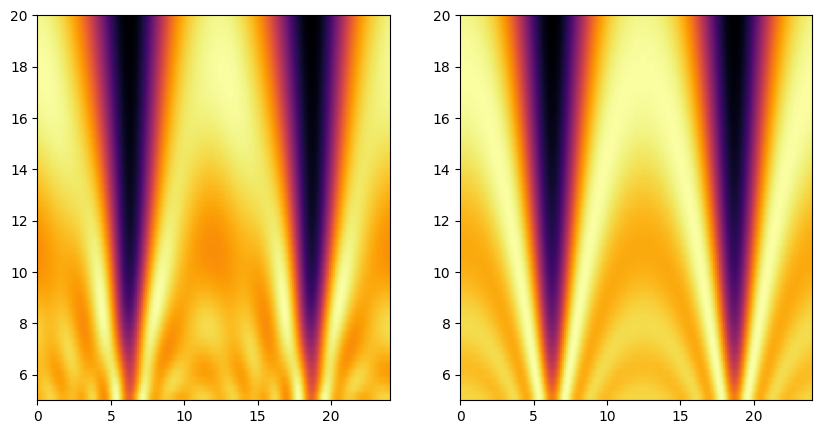

In [130]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(signal_planet, extent=(t[0]/3600, t[-1]/3600, lambdas[0]*1e6, lambdas[-1]*1e6), aspect='auto', cmap='inferno', origin = 'lower')
ax[1].imshow(signal_no_planet, extent=(t[0]/3600, t[-1]/3600, lambdas[0]*1e6, lambdas[-1]*1e6), aspect='auto', cmap='inferno', origin = 'lower')

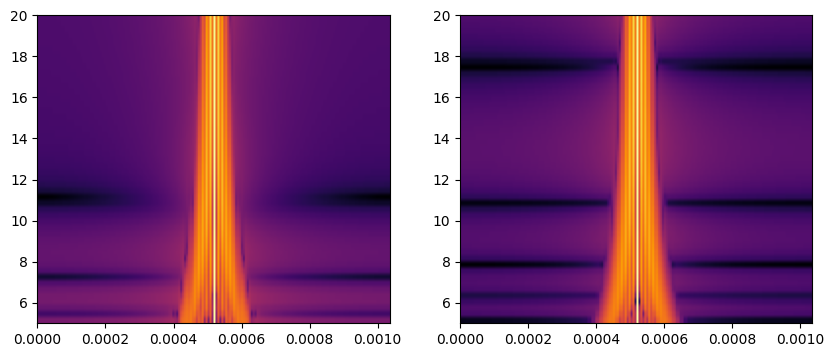

In [131]:
signal_fft_p = np.fft.fftshift(np.fft.fft(signal_planet), axes=1)
intensity_fft_p = np.abs(signal_fft_p)**2

# frequency axis for plot (x-axis in Hz)
freq = np.fft.rfftfreq(len(t), d=t[1]-t[0])

# y axis remains wavelength in microns
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(np.log(intensity_fft_p), extent=(freq[0], freq[-1], lambdas[0]*1e6, lambdas[-1]*1e6), aspect='auto', cmap='inferno', origin = 'lower')


signal_fft_no_p = np.fft.fftshift(np.fft.fft(signal_no_planet), axes=1)
intensity_fft_no_p = np.abs(signal_fft_no_p)**2


# y axis remains wavelength in microns

ax[1].imshow(np.log(intensity_fft_no_p), extent=(freq[0], freq[-1], lambdas[0]*1e6, lambdas[-1]*1e6), aspect='auto', cmap='inferno', origin = 'lower')



In [111]:
t[1] - t[0]

np.float64(872.7272727272727)

In [81]:
np.fft.fft?

Signature:       np.fft.fft(a, n=None, axis=-1, norm=None, out=None)
Call signature:  np.fft.fft(*args, **kwargs)
Type:            _ArrayFunctionDispatcher
String form:     <function fft at 0x7989130a4720>
File:            ~/miniconda3/envs/lifesim/lib/python3.12/site-packages/numpy/fft/_pocketfft.py
Docstring:      
Compute the one-dimensional discrete Fourier Transform.

This function computes the one-dimensional *n*-point discrete Fourier
Transform (DFT) with the efficient Fast Fourier Transform (FFT)
algorithm [CT]_.

Parameters
----------
a : array_like
    Input array, can be complex.
n : int, optional
    Length of the transformed axis of the output.
    If `n` is smaller than the length of the input, the input is cropped.
    If it is larger, the input is padded with zeros.  If `n` is not given,
    the length of the input along the axis specified by `axis` is used.
axis : int, optional
    Axis over which to compute the FFT.  If not given, the last axis is
    used.
norm : {"b

In [106]:
t

array([    0.        ,   872.72727273,  1745.45454545,  2618.18181818,
        3490.90909091,  4363.63636364,  5236.36363636,  6109.09090909,
        6981.81818182,  7854.54545455,  8727.27272727,  9600.        ,
       10472.72727273, 11345.45454545, 12218.18181818, 13090.90909091,
       13963.63636364, 14836.36363636, 15709.09090909, 16581.81818182,
       17454.54545455, 18327.27272727, 19200.        , 20072.72727273,
       20945.45454545, 21818.18181818, 22690.90909091, 23563.63636364,
       24436.36363636, 25309.09090909, 26181.81818182, 27054.54545455,
       27927.27272727, 28800.        , 29672.72727273, 30545.45454545,
       31418.18181818, 32290.90909091, 33163.63636364, 34036.36363636,
       34909.09090909, 35781.81818182, 36654.54545455, 37527.27272727,
       38400.        , 39272.72727273, 40145.45454545, 41018.18181818,
       41890.90909091, 42763.63636364, 43636.36363636, 44509.09090909,
       45381.81818182, 46254.54545455, 47127.27272727, 48000.        ,
      

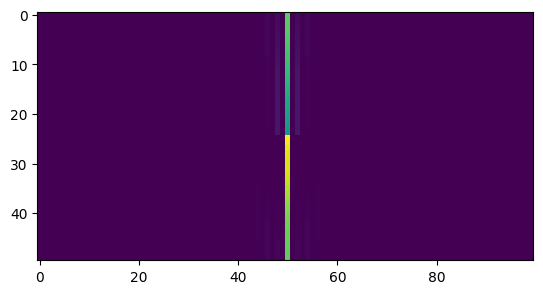

In [68]:
t/3600/24

array([0.        , 0.01010101, 0.02020202, 0.03030303, 0.04040404,
       0.05050505, 0.06060606, 0.07070707, 0.08080808, 0.09090909,
       0.1010101 , 0.11111111, 0.12121212, 0.13131313, 0.14141414,
       0.15151515, 0.16161616, 0.17171717, 0.18181818, 0.19191919,
       0.2020202 , 0.21212121, 0.22222222, 0.23232323, 0.24242424,
       0.25252525, 0.26262626, 0.27272727, 0.28282828, 0.29292929,
       0.3030303 , 0.31313131, 0.32323232, 0.33333333, 0.34343434,
       0.35353535, 0.36363636, 0.37373737, 0.38383838, 0.39393939,
       0.4040404 , 0.41414141, 0.42424242, 0.43434343, 0.44444444,
       0.45454545, 0.46464646, 0.47474747, 0.48484848, 0.49494949,
       0.50505051, 0.51515152, 0.52525253, 0.53535354, 0.54545455,
       0.55555556, 0.56565657, 0.57575758, 0.58585859, 0.5959596 ,
       0.60606061, 0.61616162, 0.62626263, 0.63636364, 0.64646465,
       0.65656566, 0.66666667, 0.67676768, 0.68686869, 0.6969697 ,
       0.70707071, 0.71717172, 0.72727273, 0.73737374, 0.74747

In [61]:
?np.fft.fft

Signature:       np.fft.fft(a, n=None, axis=-1, norm=None, out=None)
Call signature:  np.fft.fft(*args, **kwargs)
Type:            _ArrayFunctionDispatcher
String form:     <function fft at 0x7989130a4720>
File:            ~/miniconda3/envs/lifesim/lib/python3.12/site-packages/numpy/fft/_pocketfft.py
Docstring:      
Compute the one-dimensional discrete Fourier Transform.

This function computes the one-dimensional *n*-point discrete Fourier
Transform (DFT) with the efficient Fast Fourier Transform (FFT)
algorithm [CT]_.

Parameters
----------
a : array_like
    Input array, can be complex.
n : int, optional
    Length of the transformed axis of the output.
    If `n` is smaller than the length of the input, the input is cropped.
    If it is larger, the input is padded with zeros.  If `n` is not given,
    the length of the input along the axis specified by `axis` is used.
axis : int, optional
    Axis over which to compute the FFT.  If not given, the last axis is
    used.
norm : {"b

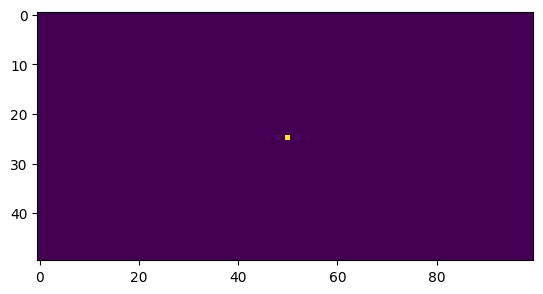

In [59]:
plt.imshow(intensity_fft)

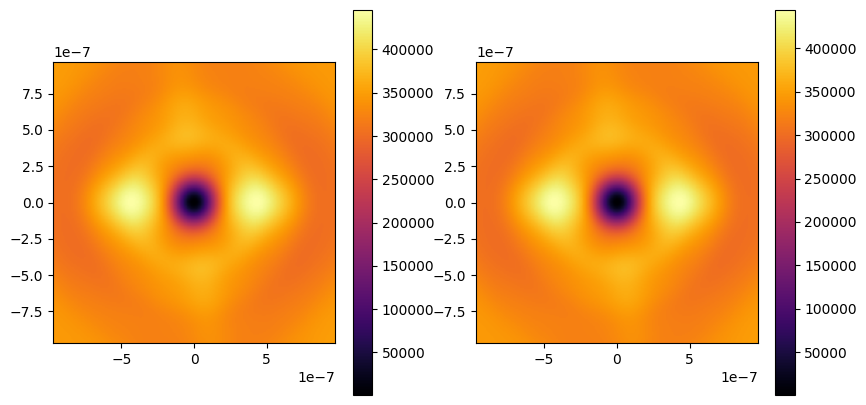

In [42]:
# Image with planet 
proj_planet = np.sum(s_SBW_lambda_scenery * signal_planet[:, :, None, None], axis = (0,1))
proj_no_planet = np.sum(s_SBW_lambda_scenery * signal_no_planet[:, :, None, None], axis = (0,1))
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(proj_planet, extent=(min(beta), max(beta), min(alpha), max(alpha)), cmap='inferno', origin = 'lower')

ax[1].imshow(proj_no_planet, extent=(min(beta), max(beta), min(alpha), max(alpha)), cmap='inferno', origin = 'lower')
# add colorbar
plt.colorbar(ax[0].imshow(proj_planet, extent=(min(beta), max(beta), min(alpha), max(alpha)), cmap='inferno', origin = 'lower'), ax=ax[0])
plt.colorbar(ax[1].imshow(proj_no_planet, extent=(min(beta), max(beta), min(alpha), max(alpha)), cmap='inferno', origin = 'lower'), ax=ax[1])


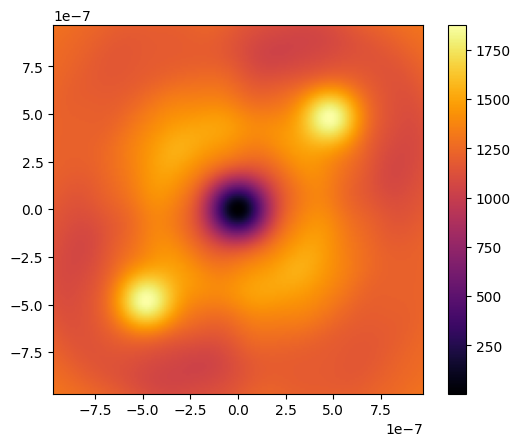

In [43]:
plt.imshow(proj_planet - proj_no_planet, extent=(min(beta), max(beta), min(alpha), max(alpha)), cmap='inferno', origin = 'lower')
plt.colorbar()

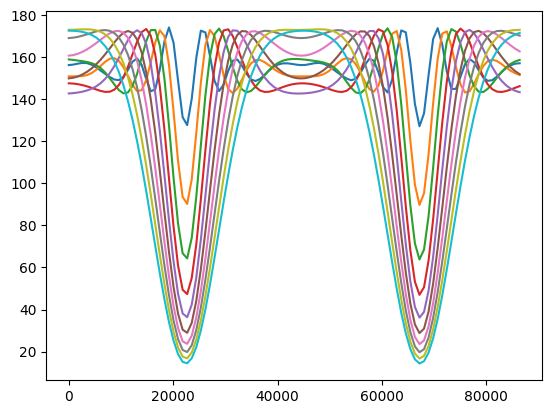

In [57]:
for i in range(0, signal_planet.shape[0], 5):
    plt.plot(t, signal_planet[i,:])

In [50]:
signal_planet.shape

(50, 100)

## Planet Signal

(100, 200)


Text(0.5, 1.0, 'Single Bracewell')

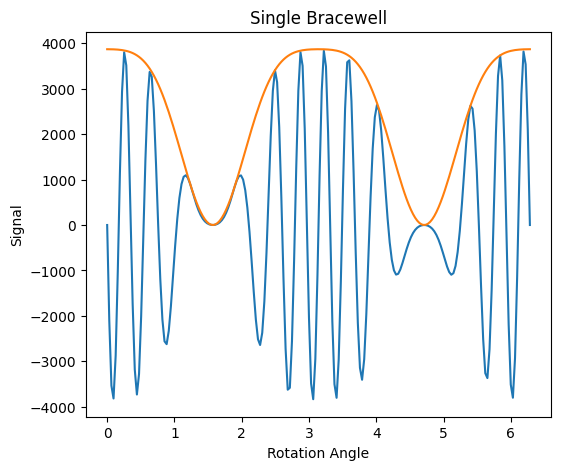

In [ ]:
rotation_angles = np.linspace(0, 2*np.pi, 200)
S_SBW = np.zeros_like(rotation_angles)
S_DBW = np.zeros_like(rotation_angles)

alpha = np.linspace(-2*planet_diameter_arcsec + planet_pos_arcsec[0], 2*planet_diameter_arcsec + planet_pos_arcsec[0], 100)
beta = np.linspace(-2*planet_diameter_arcsec + planet_pos_arcsec[1], 2*planet_diameter_arcsec + planet_pos_arcsec[1], 200)

ALPHA, BETA = np.meshgrid(alpha, beta, indexing='ij')
Im_Planet = np.zeros_like(ALPHA)
print(Im_Planet.shape)
Im_Planet[np.sqrt((ALPHA - planet_pos_arcsec[0])**2 + (BETA - planet_pos_arcsec[1])**2) < planet_diameter_arcsec] = 1

for i in range(len(rotation_angles)):
    T_planet = SBW(baseline = 10,  rot_angle=rotation_angles[i], lambda_ref=10e-6, D=4, alpha=alpha, beta=beta) #np.abs(D1)**2
    S_SBW[i] = np.sum(Im_Planet * T_planet)

    T_planet = DBW(baseline = 10,  rot_angle=rotation_angles[i], lambda_ref=10e-6, D=4, alpha=alpha, beta=beta) #np.abs(D1)**2
    S_DBW[i] = np.sum(Im_Planet * T_planet)


fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(rotation_angles, S_DBW)
ax.plot(rotation_angles, S_SBW)
ax.set_xlabel('Rotation Angle')
ax.set_ylabel('Signal')
ax.set_title('Single Bracewell')

In [ ]:
rotation_angles = np.linspace(0, 2*np.pi, 200)
wavelengths = np.linspace(4e-6, 18e-6, 100)

S_SBW = np.zeros((len(wavelengths), len(rotation_angles)))
S_DBW = np.zeros((len(wavelengths), len(rotation_angles)))

alpha = np.linspace(-2*planet_diameter_arcsec + planet_pos_arcsec[0], 2*planet_diameter_arcsec + planet_pos_arcsec[0], 200)
beta = np.linspace(-2*planet_diameter_arcsec + planet_pos_arcsec[1], 2*planet_diameter_arcsec + planet_pos_arcsec[1], 200)

ALPHA, BETA = np.meshgrid(alpha, beta, indexing='ij')
Im_Planet = np.zeros((len(alpha), len(beta), len(wavelengths)))
Im_Planet[np.sqrt((ALPHA - planet_pos_arcsec[0])**2 + (BETA - planet_pos_arcsec[1])**2) < planet_diameter_arcsec] = 1

for i in range(len(rotation_angles)):

    for j in range(len(wavelengths)):
        T_planet = SBW(baseline = 10,  rot_angle=rotation_angles[i], lambda_ref=wavelengths[j], D=4, alpha=alpha, beta=beta) #np.abs(D1)**2
        S_SBW[j, i] = np.sum(Im_Planet[:,:,j] * T_planet)

        T_planet = DBW(baseline = 10,  rot_angle=rotation_angles[i], lambda_ref=wavelengths[j], D=4, alpha=alpha, beta=beta) #np.abs(D1)**2
        S_DBW[j, i] = np.sum(Im_Planet[:,:,j] * T_planet)



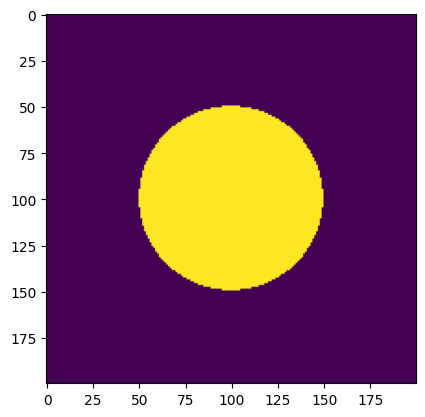

In [ ]:
plt.imshow(Im_Planet[:,:,0])

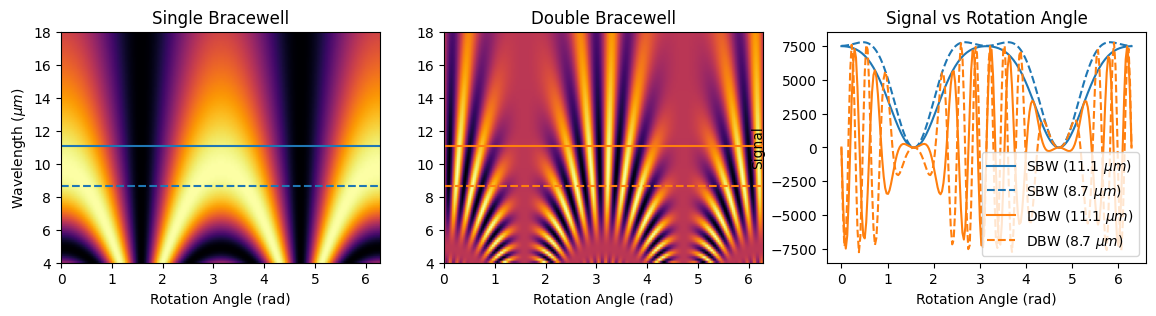

In [ ]:
fig, ax = plt.subplots(1,3,figsize=(14, 3))
ax[0].imshow(S_SBW, aspect='auto', extent=(min(rotation_angles), max(rotation_angles), min(wavelengths*1e6), max(wavelengths*1e6)), cmap='inferno', origin='lower')
ax[1].imshow(S_DBW, aspect='auto', extent=(min(rotation_angles), max(rotation_angles), min(wavelengths*1e6), max(wavelengths*1e6)), cmap='inferno', origin='lower')
ax[0].set_title('Single Bracewell')
ax[1].set_title('Double Bracewell')
ax[0].set_ylabel(r'Wavelength ($\mu m$)')
ax[0].set_xlabel('Rotation Angle (rad)')
ax[1].set_xlabel('Rotation Angle (rad)')


ax[0].hlines(wavelengths[len(wavelengths)//2]*1e6, min(rotation_angles), max(rotation_angles), color='C0', linestyle='-')
ax[0].hlines(wavelengths[len(wavelengths)//3]*1e6, min(rotation_angles), max(rotation_angles), color='C0', linestyle='--')
ax[2].plot(rotation_angles, S_SBW[len(wavelengths)//2, :], label=f'SBW ({wavelengths[len(wavelengths)//2]*1e6:.1f} ' + r'$\mu m$)', color='C0', linestyle='-')
ax[2].plot(rotation_angles, S_SBW[len(wavelengths)//3, :], label=f'SBW ({wavelengths[len(wavelengths)//3]*1e6:.1f} ' + r'$\mu m$)', color='C0', linestyle='--')

ax[1].hlines(wavelengths[len(wavelengths)//2]*1e6, min(rotation_angles), max(rotation_angles), color='C1', linestyle='-')
ax[1].hlines(wavelengths[len(wavelengths)//3]*1e6, min(rotation_angles), max(rotation_angles), color='C1', linestyle='--')
ax[2].plot(rotation_angles, S_DBW[len(wavelengths)//2, :], label=f'DBW ({wavelengths[len(wavelengths)//2]*1e6:.1f} ' + r'$\mu m$)', color='C1', linestyle='-')
ax[2].plot(rotation_angles, S_DBW[len(wavelengths)//3, :], label=f'DBW ({wavelengths[len(wavelengths)//3]*1e6:.1f} ' + r'$\mu m$)', color='C1', linestyle='--')

ax[2].set_xlabel('Rotation Angle (rad)')
ax[2].set_ylabel('Signal')
ax[2].set_title('Signal vs Rotation Angle')
ax[2].legend()
plt.savefig('Plots/planet_sbw_dbw.pdf', dpi=300, bbox_inches='tight')


# Star Signal

In [ ]:
rotation_angles = np.linspace(0, 2*np.pi, 200)
wavelengths = np.linspace(4e-6, 18e-6, 100)

S_SBW = np.zeros((len(wavelengths), len(rotation_angles)))
S_DBW = np.zeros((len(wavelengths), len(rotation_angles)))

alpha = np.linspace(-2*diameter_star_arcsec , 2*diameter_star_arcsec, 200)
beta = np.linspace(-2*diameter_star_arcsec , 2*diameter_star_arcsec , 200)

ALPHA, BETA = np.meshgrid(alpha, beta, indexing='ij')
Im_Star = np.zeros((len(alpha), len(beta), len(wavelengths)))
Im_Star[np.sqrt(ALPHA**2 + BETA**2) < diameter_star_arcsec] = 1


for i in range(len(rotation_angles)):

    for j in range(len(wavelengths)):
        T_star = SBW(baseline = 10,  rot_angle=rotation_angles[i], lambda_ref=wavelengths[j], D=4, alpha=alpha, beta=beta) #np.abs(D1)**2
        S_SBW[j, i] = np.sum(Im_Star[:,:,j] * T_star)

        T_star = DBW(baseline = 10,  rot_angle=rotation_angles[i], lambda_ref=wavelengths[j], D=4, alpha=alpha, beta=beta) #np.abs(D1)**2
        S_DBW[j, i] = np.sum(Im_Star[:,:,j] * T_star)



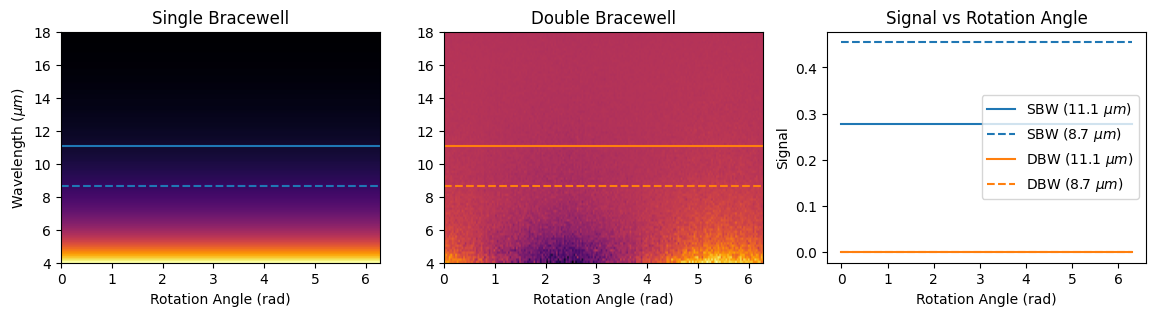

In [ ]:
fig, ax = plt.subplots(1,3,figsize=(14, 3))
ax[0].imshow(S_SBW, aspect='auto', extent=(min(rotation_angles), max(rotation_angles), min(wavelengths*1e6), max(wavelengths*1e6)), cmap='inferno', origin='lower')
ax[1].imshow(S_DBW, aspect='auto', extent=(min(rotation_angles), max(rotation_angles), min(wavelengths*1e6), max(wavelengths*1e6)), cmap='inferno', origin='lower')
ax[0].set_title('Single Bracewell')
ax[1].set_title('Double Bracewell')
ax[0].set_ylabel(r'Wavelength ($\mu m$)')
ax[0].set_xlabel('Rotation Angle (rad)')
ax[1].set_xlabel('Rotation Angle (rad)')

ax[0].hlines(wavelengths[len(wavelengths)//2]*1e6, min(rotation_angles), max(rotation_angles), color='C0', linestyle='-')
ax[0].hlines(wavelengths[len(wavelengths)//3]*1e6, min(rotation_angles), max(rotation_angles), color='C0', linestyle='--')
ax[2].plot(rotation_angles, S_SBW[len(wavelengths)//2, :], label=f'SBW ({wavelengths[len(wavelengths)//2]*1e6:.1f} ' + r'$\mu m$)', color='C0', linestyle='-')
ax[2].plot(rotation_angles, S_SBW[len(wavelengths)//3, :], label=f'SBW ({wavelengths[len(wavelengths)//3]*1e6:.1f} ' + r'$\mu m$)', color='C0', linestyle='--')

ax[1].hlines(wavelengths[len(wavelengths)//2]*1e6, min(rotation_angles), max(rotation_angles), color='C1', linestyle='-')
ax[1].hlines(wavelengths[len(wavelengths)//3]*1e6, min(rotation_angles), max(rotation_angles), color='C1', linestyle='--')
ax[2].plot(rotation_angles, S_DBW[len(wavelengths)//2, :], label=f'DBW ({wavelengths[len(wavelengths)//2]*1e6:.1f} ' + r'$\mu m$)', color='C1', linestyle='-')
ax[2].plot(rotation_angles, S_DBW[len(wavelengths)//3, :], label=f'DBW ({wavelengths[len(wavelengths)//3]*1e6:.1f} ' + r'$\mu m$)', color='C1', linestyle='--')

ax[2].set_xlabel('Rotation Angle (rad)')
ax[2].set_ylabel('Signal')
ax[2].set_title('Signal vs Rotation Angle')
ax[2].legend()
plt.savefig('Plots/star_sbw_dbw.pdf', dpi=300, bbox_inches='tight')



## Exo Zodi

In [ ]:
rotation_angles = np.linspace(0, 2*np.pi, 200)
wavelengths = np.linspace(4e-6, 18e-6, 20)
diameter_exozodi = 0.1

S_SBW = np.zeros((len(wavelengths), len(rotation_angles)))
S_DBW = np.zeros((len(wavelengths), len(rotation_angles)))

alpha = np.linspace(-2*diameter_exozodi , 2*diameter_exozodi, 100)
beta = np.linspace(-2*diameter_exozodi , 2*diameter_exozodi , 100)

ALPHA, BETA = np.meshgrid(alpha, beta, indexing='ij')
inc = 20 * (np.pi/180)
phi = 0 * (np.pi/180)
ALPHA_rot = ALPHA * np.cos(phi) + BETA * np.sin(phi)
BETA_rot = 1/np.cos(inc) * (-ALPHA * np.sin(phi) + BETA * np.cos(phi))
Im_ez = np.zeros((len(alpha), len(beta), len(wavelengths)))
Im_ez[np.sqrt(ALPHA_rot**2 + BETA_rot**2) < diameter_exozodi] = 1


for i in range(len(rotation_angles)):

    for j in range(len(wavelengths)):
        T_ez = SBW(baseline = 10,  rot_angle=rotation_angles[i], lambda_ref=wavelengths[j], D=4, alpha=alpha, beta=beta) #np.abs(D1)**2
        S_SBW[j, i] = np.sum(Im_ez[:,:,j] * T_ez)

        T_ez = DBW(baseline = 10,  rot_angle=rotation_angles[i], lambda_ref=wavelengths[j], D=4, alpha=alpha, beta=beta) #np.abs(D1)**2
        S_DBW[j, i] = np.sum(Im_ez[:,:,j] * T_ez)


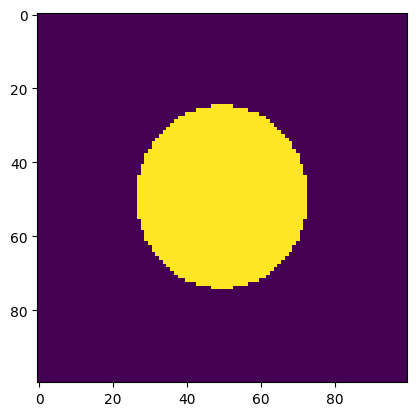

In [ ]:
plt.imshow(Im_ez[:,:,0])

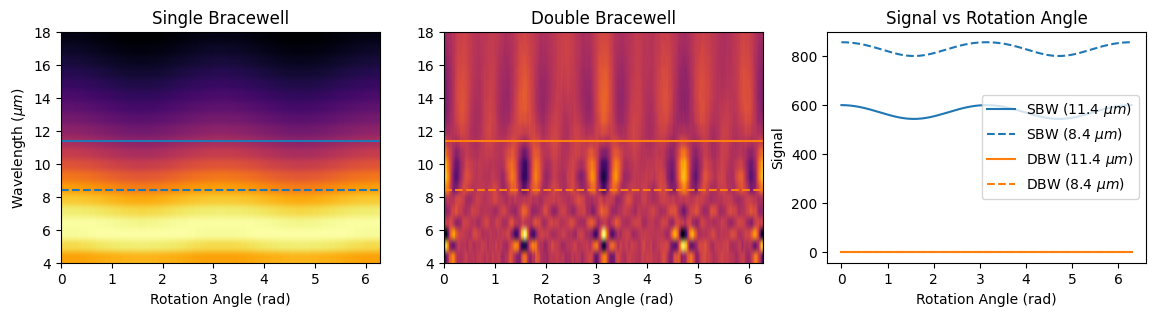

In [ ]:
fig, ax = plt.subplots(1,3,figsize=(14, 3))
ax[0].imshow(S_SBW, aspect='auto', extent=(min(rotation_angles), max(rotation_angles), min(wavelengths*1e6), max(wavelengths*1e6)), cmap='inferno', origin='lower')
ax[1].imshow(S_DBW, aspect='auto', extent=(min(rotation_angles), max(rotation_angles), min(wavelengths*1e6), max(wavelengths*1e6)), cmap='inferno', origin='lower')
ax[0].set_title('Single Bracewell')
ax[1].set_title('Double Bracewell')
ax[0].set_ylabel(r'Wavelength ($\mu m$)')
ax[0].set_xlabel('Rotation Angle (rad)')
ax[1].set_xlabel('Rotation Angle (rad)')

ax[0].hlines(wavelengths[len(wavelengths)//2]*1e6, min(rotation_angles), max(rotation_angles), color='C0', linestyle='-')
ax[0].hlines(wavelengths[len(wavelengths)//3]*1e6, min(rotation_angles), max(rotation_angles), color='C0', linestyle='--')
ax[2].plot(rotation_angles, S_SBW[len(wavelengths)//2, :], label=f'SBW ({wavelengths[len(wavelengths)//2]*1e6:.1f} ' + r'$\mu m$)', color='C0', linestyle='-')
ax[2].plot(rotation_angles, S_SBW[len(wavelengths)//3, :], label=f'SBW ({wavelengths[len(wavelengths)//3]*1e6:.1f} ' + r'$\mu m$)', color='C0', linestyle='--')

ax[1].hlines(wavelengths[len(wavelengths)//2]*1e6, min(rotation_angles), max(rotation_angles), color='C1', linestyle='-')
ax[1].hlines(wavelengths[len(wavelengths)//3]*1e6, min(rotation_angles), max(rotation_angles), color='C1', linestyle='--')
ax[2].plot(rotation_angles, S_DBW[len(wavelengths)//2, :], label=f'DBW ({wavelengths[len(wavelengths)//2]*1e6:.1f} ' + r'$\mu m$)', color='C1', linestyle='-')
ax[2].plot(rotation_angles, S_DBW[len(wavelengths)//3, :], label=f'DBW ({wavelengths[len(wavelengths)//3]*1e6:.1f} ' + r'$\mu m$)', color='C1', linestyle='--')

ax[2].set_xlabel('Rotation Angle (rad)')
ax[2].set_ylabel('Signal')
ax[2].set_title('Signal vs Rotation Angle')
ax[2].legend()
plt.savefig('Plots/exozodi_face_on_sbw_dbw.pdf', dpi=300, bbox_inches='tight')

In [ ]:
rotation_angles = np.linspace(0, 2*np.pi, 200)
wavelengths = np.linspace(4e-6, 18e-6, 50)
diameter_exozodi = 0.1

S_SBW = np.zeros((len(wavelengths), len(rotation_angles)))
S_DBW = np.zeros((len(wavelengths), len(rotation_angles)))

alpha = np.linspace(-2*diameter_exozodi , 2*diameter_exozodi, 100)
beta = np.linspace(-2*diameter_exozodi , 2*diameter_exozodi , 100)

ALPHA, BETA = np.meshgrid(alpha, beta, indexing='ij')
inc = 70 * (np.pi/180)
phi = 0 * (np.pi/180)
ALPHA_rot = ALPHA * np.cos(phi) + BETA * np.sin(phi)
BETA_rot = 1/np.cos(inc) * (-ALPHA * np.sin(phi) + BETA * np.cos(phi))
Im_ez = np.zeros((len(alpha), len(beta), len(wavelengths)))
Im_ez[np.sqrt(ALPHA_rot**2 + BETA_rot**2) < diameter_exozodi] = 1


for i in range(len(rotation_angles)):

    for j in range(len(wavelengths)):
        T_ez = SBW(baseline = 10,  rot_angle=rotation_angles[i], lambda_ref=wavelengths[j], D=4, alpha=alpha, beta=beta) #np.abs(D1)**2
        S_SBW[j, i] = np.sum(Im_ez[:,:,j] * T_ez)

        T_ez = DBW(baseline = 10,  rot_angle=rotation_angles[i], lambda_ref=wavelengths[j], D=4, alpha=alpha, beta=beta) #np.abs(D1)**2
        S_DBW[j, i] = np.sum(Im_ez[:,:,j] * T_ez)


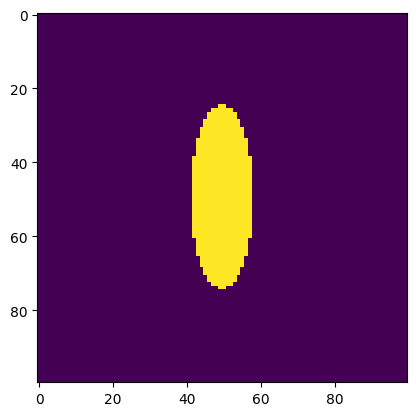

In [ ]:
plt.imshow(Im_ez[:,:,0])

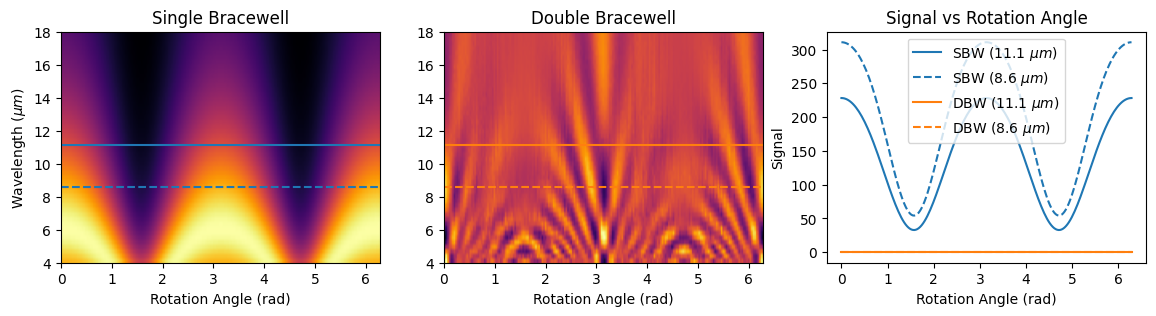

In [ ]:
fig, ax = plt.subplots(1,3,figsize=(14, 3))
ax[0].imshow(S_SBW, aspect='auto', extent=(min(rotation_angles), max(rotation_angles), min(wavelengths*1e6), max(wavelengths*1e6)), cmap='inferno', origin='lower')
ax[1].imshow(S_DBW, aspect='auto', extent=(min(rotation_angles), max(rotation_angles), min(wavelengths*1e6), max(wavelengths*1e6)), cmap='inferno', origin='lower')
ax[0].set_title('Single Bracewell')
ax[1].set_title('Double Bracewell')
ax[0].set_ylabel(r'Wavelength ($\mu m$)')
ax[0].set_xlabel('Rotation Angle (rad)')
ax[1].set_xlabel('Rotation Angle (rad)')

ax[0].hlines(wavelengths[len(wavelengths)//2]*1e6, min(rotation_angles), max(rotation_angles), color='C0', linestyle='-')
ax[0].hlines(wavelengths[len(wavelengths)//3]*1e6, min(rotation_angles), max(rotation_angles), color='C0', linestyle='--')
ax[2].plot(rotation_angles, S_SBW[len(wavelengths)//2, :], label=f'SBW ({wavelengths[len(wavelengths)//2]*1e6:.1f} ' + r'$\mu m$)', color='C0', linestyle='-')
ax[2].plot(rotation_angles, S_SBW[len(wavelengths)//3, :], label=f'SBW ({wavelengths[len(wavelengths)//3]*1e6:.1f} ' + r'$\mu m$)', color='C0', linestyle='--')

ax[1].hlines(wavelengths[len(wavelengths)//2]*1e6, min(rotation_angles), max(rotation_angles), color='C1', linestyle='-')
ax[1].hlines(wavelengths[len(wavelengths)//3]*1e6, min(rotation_angles), max(rotation_angles), color='C1', linestyle='--')
ax[2].plot(rotation_angles, S_DBW[len(wavelengths)//2, :], label=f'DBW ({wavelengths[len(wavelengths)//2]*1e6:.1f} ' + r'$\mu m$)', color='C1', linestyle='-')
ax[2].plot(rotation_angles, S_DBW[len(wavelengths)//3, :], label=f'DBW ({wavelengths[len(wavelengths)//3]*1e6:.1f} ' + r'$\mu m$)', color='C1', linestyle='--')

ax[2].set_xlabel('Rotation Angle (rad)')
ax[2].set_ylabel('Signal')
ax[2].set_title('Signal vs Rotation Angle')
ax[2].legend()
plt.savefig('Plots/exozodi_edge_on_sbw_dbw.pdf', dpi=300, bbox_inches='tight')


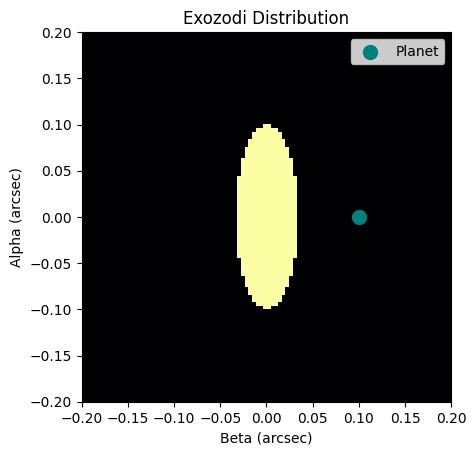

In [ ]:
plt.imshow(Im_ez[:,:,0], extent=(min(beta), max(beta), min(alpha), max(alpha)), cmap='inferno')
plt.scatter(planet_pos_arcsec[0], planet_pos_arcsec[1], color='teal', label='Planet', s=100)
plt.xlabel('Beta (arcsec)')
plt.ylabel('Alpha (arcsec)')
plt.title('Exozodi Distribution')
plt.legend()
plt.show()
